# Thí nghiệm Decision Tree – bộ feature sạch (Ames Housing)

* **Feature:** toàn bộ cột trong `cleaned_data.csv` **trừ `Id`** (80 feature), chưa chọn lọc, chưa tạo feature mới.
* **Target:** `SalePrice` **giữ nguyên đơn vị USD, không `log1p`**.
* **Không scale** (cây quyết định không phụ thuộc thang đo). Chỉ mã hóa các cột phân loại thành số để cây đọc được.
* **Chia dữ liệu:** train/valid = 80/20, `random_state=42`, giống `preprocessing/pre.ipynb` để so sánh công bằng với baseline.
* Chọn `max_depth` bằng cross-validation **trên tập train**; tập valid chỉ dùng để báo cáo.

## Params

In [1]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
DEPTHS = list(range(1, 21)) + [None]   # None = không giới hạn độ sâu

## import thư viện

In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")
Path("figures").mkdir(exist_ok=True)

## Đọc dữ liệu

Lưu ý: nhãn `None` (ví dụ `MasVnrType = None` nghĩa là không ốp tường) sẽ bị `read_csv` hiểu nhầm thành giá trị thiếu, nên phải đọc với `keep_default_na=False`.

In [3]:
df = pd.read_csv("data/cleaned_data.csv", keep_default_na=False, na_values=[""])
ids = df["Id"]
df = df.drop(columns="Id")

print(df.shape)
print("NaN còn lại:", int(df.isna().sum().sum()))
print("MasVnrType:", df["MasVnrType"].value_counts().to_dict())

(1458, 81)
NaN còn lại: 0
MasVnrType: {'None': 859, 'BrkFace': 445, 'Stone': 126, 'BrkCmn': 15, 'Unknown': 13}


## Tách X, y và chia train / valid

In [4]:
X = df.drop(columns="SalePrice")
y = df["SalePrice"]          # giữ nguyên USD, KHÔNG log1p

X_train, X_valid, y_train, y_valid, id_train, id_valid = train_test_split(
    X, y, ids, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape, "| X_valid:", X_valid.shape)
print("Số feature:", X.shape[1])

# kiểm tra tập valid trùng đúng với tập valid của baseline (pre.ipynb)
y_valid_baseline = pd.read_csv("../../../data/processed/y_test.csv")["SalePrice"]
assert (y_valid.values == y_valid_baseline.values).all()
print("Tập valid trùng với baseline: OK")

X_train: (1166, 80) | X_valid: (292, 80)
Số feature: 80
Tập valid trùng với baseline: OK


## Mã hóa cột phân loại

Dùng đúng nhóm mã hóa của `pre.ipynb`, nhưng áp cho **toàn bộ** feature sạch:
* Các cột chất lượng có thứ tự (`ExterQual`, `ExterCond`, `KitchenQual`, `HeatingQC`, `BsmtQual`, `BsmtCond`, `GarageQual`, `GarageCond`, `FireplaceQu`): Ordinal theo thứ tự `Po < Fa < TA < Gd < Ex`.
* Các cột phân loại còn lại (kể cả `MSSubClass`, `MoSold` vì là mã, không phải số đo): One-Hot.
* Các cột số: giữ nguyên, không scale.

In [5]:
quality = ["Po", "Fa", "TA", "Gd", "Ex"]
ORDINAL = {
    "ExterQual": quality, "ExterCond": quality, "KitchenQual": quality, "HeatingQC": quality,
    "BsmtQual": ["No Basement"] + quality, "BsmtCond": ["No Basement"] + quality,
    "GarageQual": ["No Garage"] + quality, "GarageCond": ["No Garage"] + quality,
    "FireplaceQu": ["No Fireplace"] + quality,
}
ordinal_cols = list(ORDINAL)
nominal_cols = [c for c in X.select_dtypes(exclude="number").columns if c not in ORDINAL] + ["MSSubClass", "MoSold"]
numeric_cols = [c for c in X.columns if c not in ordinal_cols + nominal_cols]

# mọi giá trị của cột ordinal phải nằm trong thứ tự đã khai báo (nếu không sẽ bị mã hóa thành -1 âm thầm)
for col, order in ORDINAL.items():
    unseen = set(X[col].unique()) - set(order)
    assert not unseen, (col, unseen)

print(f"ordinal: {len(ordinal_cols)} | one-hot: {len(nominal_cols)} | số giữ nguyên: {len(numeric_cols)}")


def make_pipeline(**tree_params):
    encoder = ColumnTransformer(
        [
            ("ordinal", OrdinalEncoder(categories=[ORDINAL[c] for c in ordinal_cols],
                                       handle_unknown="use_encoded_value", unknown_value=-1), ordinal_cols),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
            ("numeric", "passthrough", numeric_cols),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")
    return Pipeline([("encoder", encoder), ("tree", DecisionTreeRegressor(random_state=RANDOM_STATE, **tree_params))])

ordinal: 9 | one-hot: 36 | số giữ nguyên: 35


## Run 1 – Decision Tree mặc định (không giới hạn độ sâu)

`RMSLE` được tính từ dự đoán USD (`log1p` chỉ dùng để chấm điểm, không dùng để huấn luyện) để so sánh với điểm Kaggle.

In [6]:
def evaluate(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "RMSLE": np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred))),
    }


run1 = make_pipeline().fit(X_train, y_train)
pred1_train, pred1_valid = run1.predict(X_train), run1.predict(X_valid)

tree1 = run1.named_steps["tree"]
print("Số feature sau mã hóa:", run1.named_steps["encoder"].get_feature_names_out().size)
print("Độ sâu:", tree1.get_depth(), "| Số lá:", tree1.get_n_leaves())

res_run1 = pd.DataFrame({"train": evaluate(y_train, pred1_train), "valid": evaluate(y_valid, pred1_valid)}).T
res_run1.round({"RMSE": 0, "MAE": 0, "R2": 4, "RMSLE": 4})

Số feature sau mã hóa: 288
Độ sâu: 22 | Số lá: 1126


,RMSE,MAE,R2,RMSLE
train,0.0,0.0,1.0000,0.0000
valid,40259.0,27923.0,0.7066,0.2125


**Nhận xét:**
- Cây không giới hạn độ sâu có độ sâu 22 và 1.126 lá cho 1.166 mẫu train, tức gần như mỗi lá chứa một căn nhà: **học thuộc tập train** (RMSE train = 0, R² = 1).
- Trên valid: RMSE 40.259 USD, MAE 27.923 USD, R² 0,7066, RMSLE 0,2125. Khoảng cách giữa train và valid là dấu hiệu overfitting rõ rệt.
- Tốt hơn baseline cũ (RMSE 43.635, RMSLE 0,2272), nhưng baseline khác cả bộ feature lẫn cách xử lý target, và valid chỉ có 292 dòng, nên **chưa thể kết luận** việc dùng bộ feature sạch hay bỏ `log1p` là nguyên nhân của chênh lệch này.

## Run 2 – Quét `max_depth` bằng cross-validation

Mỗi độ sâu được chấm bằng RMSE trung bình của 5-fold CV **chỉ trên tập train**. Độ sâu chọn là độ sâu có CV RMSE nhỏ nhất; cột `valid` chỉ để quan sát, không dùng để chọn.

In [7]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

rows = []
for depth in DEPTHS:
    pipe = make_pipeline(max_depth=depth)
    cv_rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    pipe.fit(X_train, y_train)
    rows.append({
        "max_depth": depth if depth is not None else "None",
        "CV RMSE": cv_rmse.mean(),
        "CV std": cv_rmse.std(),
        "Train RMSE": evaluate(y_train, pipe.predict(X_train))["RMSE"],
        "Valid RMSE": evaluate(y_valid, pipe.predict(X_valid))["RMSE"],
    })

sweep = pd.DataFrame(rows)
best_row = sweep.loc[sweep["CV RMSE"].idxmin()]
best_depth = None if best_row["max_depth"] == "None" else int(best_row["max_depth"])
print("max_depth chọn theo CV:", best_depth)
sweep.round(0)

max_depth chọn theo CV: 6


,max_depth,CV RMSE,CV std,Train RMSE,Valid RMSE
0,1,59459.0,4959.0,59459.0,54553.0
1,2,52659.0,4293.0,48115.0,46899.0
2,3,44937.0,3655.0,39165.0,43835.0
3,4,40172.0,2856.0,33577.0,40955.0
4,5,38287.0,3760.0,28892.0,37437.0
5,6,36406.0,3031.0,24568.0,38299.0
6,7,37172.0,4053.0,19880.0,40092.0
7,8,37890.0,4353.0,15710.0,41003.0
8,9,38473.0,3107.0,12341.0,38093.0
9,10,39045.0,4655.0,9540.0,37850.0


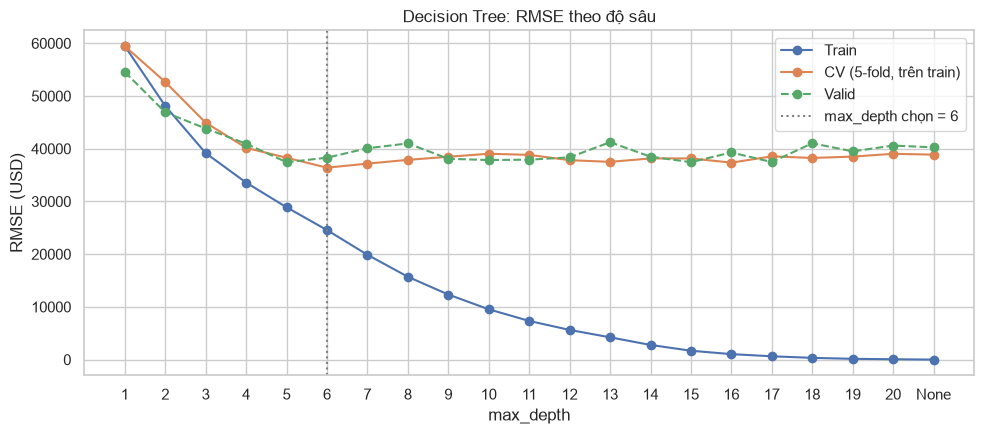

In [8]:
x = list(range(len(sweep)))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(x, sweep["Train RMSE"], marker="o", label="Train")
ax.plot(x, sweep["CV RMSE"], marker="o", label="CV (5-fold, trên train)")
ax.plot(x, sweep["Valid RMSE"], marker="o", label="Valid", linestyle="--")
ax.axvline(sweep["CV RMSE"].idxmin(), color="gray", linestyle=":", label=f"max_depth chọn = {best_depth}")
ax.set_xticks(x)
ax.set_xticklabels(sweep["max_depth"].astype(str))
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE (USD)")
ax.set_title("Decision Tree: RMSE theo độ sâu")
ax.legend()
plt.tight_layout()
plt.savefig("figures/decision_tree_depth_curve.png", dpi=150)
plt.show()

**Nhận xét:**
- RMSE train giảm đều theo độ sâu (59.459 ở độ sâu 1 xuống 0), còn CV RMSE giảm mạnh đến độ sâu 6 (36.406) rồi đi ngang, dao động quanh 37.000–39.000. Độ sâu 1–4 bị underfit (CV RMSE ≥ 40.172).
- Từ độ sâu 5 trở đi, chênh lệch CV RMSE giữa các độ sâu **nhỏ hơn độ lệch chuẩn giữa các fold** (khoảng 2.400–4.400), nên việc chọn độ sâu 6 là hợp lý nhưng không hơn các độ sâu 5, 12, 13 hay 16 một cách có ý nghĩa.
- RMSE valid dao động 37.400–41.200 từ độ sâu 5 trở đi và không có xu hướng rõ, nên không dùng nó để chọn độ sâu.

## Run 3 – Cây với `max_depth` chọn theo CV

So sánh với Run 1 và với baseline Decision Tree cũ (feature đã xử lý ở `processed/`, target `log1p`, tham số mặc định).

In [9]:
run3 = make_pipeline(max_depth=best_depth).fit(X_train, y_train)
pred3_train, pred3_valid = run3.predict(X_train), run3.predict(X_valid)

base = pd.read_csv("../../baseline/baseline_scores.csv")
base = base[base["model"] == "Decision Tree"].set_index("split")

compare = pd.DataFrame({
    "Baseline cũ (processed + log1p)": base.loc["valid", ["RMSE", "MAE", "R2", "RMSLE"]],
    "Run 1 (mặc định)": evaluate(y_valid, pred1_valid),
    f"Run 3 (max_depth={best_depth})": evaluate(y_valid, pred3_valid),
}).T.astype(float)
compare["RMSE train"] = [base.loc["train", "RMSE"], evaluate(y_train, pred1_train)["RMSE"], evaluate(y_train, pred3_train)["RMSE"]]
compare.round({"RMSE": 0, "MAE": 0, "R2": 4, "RMSLE": 4, "RMSE train": 0})

,RMSE,MAE,R2,RMSLE,RMSE train
Baseline cũ (processed + log1p),43635.0,29943.0,0.6553,0.2272,232.0
Run 1 (mặc định),40259.0,27923.0,0.7066,0.2125,0.0
Run 3 (max_depth=6),38299.0,26930.0,0.7345,0.2081,24568.0


**Nhận xét:**
- Cây độ sâu 6 cho RMSE valid 38.299 USD, MAE 26.930 USD, R² 0,7345 và RMSLE 0,2081, với RMSE train 24.568: khoảng cách train–valid đã nhỏ hơn nhiều so với Run 1.
- Cải thiện so với Run 1 (RMSE 40.259 xuống 38.299, khoảng 5%) **nhỏ so với độ nhiễu của CV** (độ lệch chuẩn khoảng 3.000), nên chỉ nên coi là "giới hạn độ sâu giúp bớt overfitting" chứ không phải bằng chứng một cấu hình tốt hơn hẳn.
- So với baseline cũ (RMSE 43.635, RMSLE 0,2272), cả hai run đều tốt hơn, nhưng cần nhớ đây là so sánh gộp hai thay đổi (bộ feature và target), trên một lần chia dữ liệu.

## Feature quan trọng và dự đoán so với thực tế

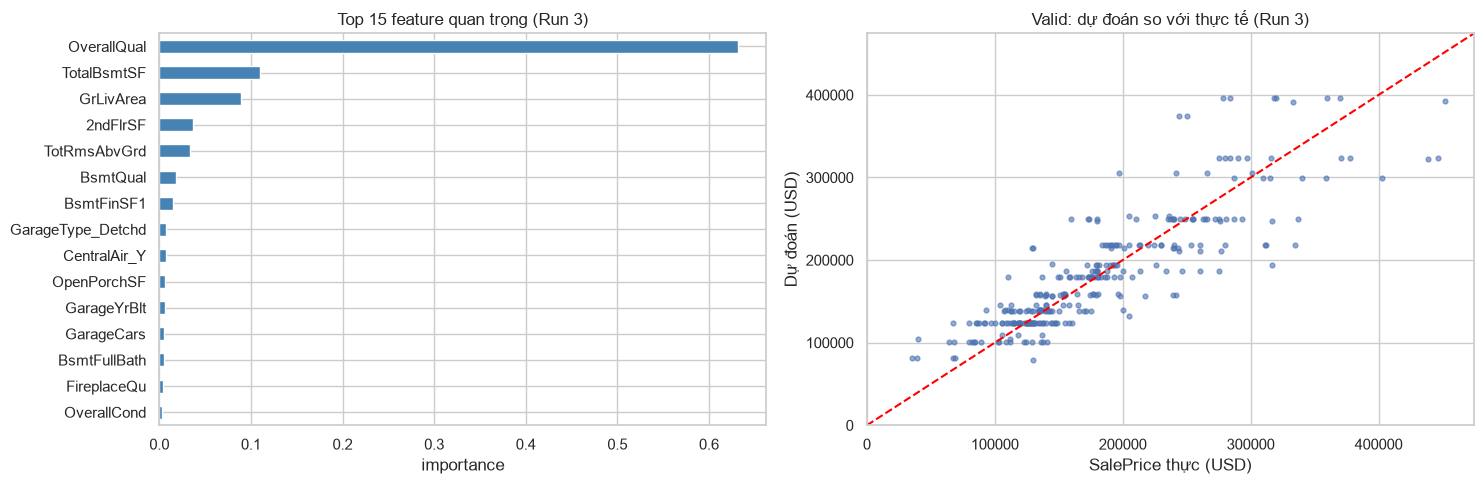

,importance
OverallQual,0.6312
TotalBsmtSF,0.1104
GrLivArea,0.0888
2ndFlrSF,0.0362
TotRmsAbvGrd,0.0334
BsmtQual,0.0179
BsmtFinSF1,0.0152
GarageType_Detchd,0.0078
CentralAir_Y,0.0073
OpenPorchSF,0.0066


In [10]:
encoded_names = run3.named_steps["encoder"].get_feature_names_out()
importance = (pd.Series(run3.named_steps["tree"].feature_importances_, index=encoded_names)
              .sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
importance.head(15)[::-1].plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Top 15 feature quan trọng (Run 3)")
axes[0].set_xlabel("importance")

axes[1].scatter(y_valid, pred3_valid, s=12, alpha=0.6)
lim = [0, max(y_valid.max(), pred3_valid.max()) * 1.05]
axes[1].plot(lim, lim, color="red", linestyle="--")
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("SalePrice thực (USD)"); axes[1].set_ylabel("Dự đoán (USD)")
axes[1].set_title("Valid: dự đoán so với thực tế (Run 3)")
plt.tight_layout()
plt.savefig("figures/decision_tree_importance_pred.png", dpi=150)
plt.show()

importance.head(10).round(4).to_frame("importance")

**Nhận xét:**
- `OverallQual` chiếm 63,1% độ quan trọng; cùng `TotalBsmtSF` (11,0%), `GrLivArea` (8,9%), `2ndFlrSF` (3,6%) và `TotRmsAbvGrd` (3,3%) thì 5 feature này chiếm khoảng 90%. Kết quả phù hợp với EDA: chất lượng tổng thể và diện tích là yếu tố quyết định giá.
- Cây chỉ đọc một số ít trong 288 cột sau mã hóa; phần lớn cột One-Hot không được dùng đến.
- Biểu đồ dự đoán dạng **bậc thang**: cây độ sâu 6 chỉ có tối đa 64 lá nên trên valid chỉ có 34 giá trị dự đoán khác nhau. Dự đoán cao nhất là 396.049 USD trong khi giá thực cao nhất là 451.950 USD, và sai lệch xảy ra ở cả hai chiều với nhà đắt.
- Sai số lớn nhất khoảng 131.000 USD; 14,7% nhà trên valid sai lệch trên 50.000 USD, trung vị sai số tuyệt đối 18.227 USD.
- Một cây đơn lẻ bị giới hạn về độ mịn của dự đoán. Hướng thử tiếp theo: `min_samples_leaf`, `ccp_alpha`, hoặc các mô hình tổ hợp (Random Forest, XGBoost đã có ở baseline).

# Lưu kết quả

Lưu tham số, model, dự đoán trên valid và nhật ký thí nghiệm Excel (`Working_details_DecisionTree_Clean.xlsx`). Phần ghi Excel dùng hàm tối giản nên không cần cài `openpyxl`.

In [11]:
# 1. tham số của cây cuối cùng (Run 3)
params = run3.named_steps["tree"].get_params()
with open("decision_tree_params.json", "w", encoding="utf-8") as f:
    json.dump(params, f, indent=4, ensure_ascii=False)

# 2. model (gồm cả bước mã hóa)
joblib.dump(run3, "decision_tree_model.pkl")

# 3. dự đoán trên tập valid
pd.DataFrame({
    "Id": id_valid.values, "SalePrice": y_valid.values,
    "pred_run1": pred1_valid, "pred_run3": pred3_valid,
    "abs_error_run3": np.abs(y_valid.values - pred3_valid),
}).to_csv("data/valid_predictions.csv", index=False)
print("Đã lưu params, model, dự đoán valid")

Đã lưu params, model, dự đoán valid


In [12]:
import zipfile
from xml.sax.saxutils import escape


def col_letter(i):
    s = ""
    i += 1
    while i:
        i, r = divmod(i - 1, 26)
        s = chr(65 + r) + s
    return s


def write_xlsx(path, sheet_name, rows, header_rows, widths):
    """Ghi 1 sheet Excel tối giản (chuỗi + số), header_rows là chỉ số dòng (0-based) cần in đậm."""
    xml_rows = []
    for r, row in enumerate(rows):
        cells = []
        for c, v in enumerate(row):
            if v is None or v == "":
                continue
            ref = f"{col_letter(c)}{r + 1}"
            style = ' s="1"' if r in header_rows else ""
            if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
                cells.append(f'<c r="{ref}"{style}><v>{float(v)}</v></c>')
            else:
                cells.append(f'<c r="{ref}"{style} t="inlineStr"><is><t xml:space="preserve">{escape(str(v))}</t></is></c>')
        xml_rows.append(f'<row r="{r + 1}">{"".join(cells)}</row>')
    cols = "".join(f'<col min="{i + 1}" max="{i + 1}" width="{w}" customWidth="1"/>' for i, w in enumerate(widths))
    sheet = ('<?xml version="1.0" encoding="UTF-8" standalone="yes"?>'
             '<worksheet xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main">'
             f'<cols>{cols}</cols><sheetData>{"".join(xml_rows)}</sheetData></worksheet>')
    styles = ('<?xml version="1.0" encoding="UTF-8" standalone="yes"?>'
              '<styleSheet xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main">'
              '<fonts count="2"><font><sz val="11"/><name val="Calibri"/></font>'
              '<font><b/><sz val="11"/><name val="Calibri"/></font></fonts>'
              '<fills count="3"><fill><patternFill patternType="none"/></fill><fill><patternFill patternType="gray125"/></fill>'
              '<fill><patternFill patternType="solid"><fgColor rgb="FFD9E1F2"/></patternFill></fill></fills>'
              '<borders count="1"><border><left/><right/><top/><bottom/><diagonal/></border></borders>'
              '<cellStyleXfs count="1"><xf numFmtId="0" fontId="0" fillId="0" borderId="0"/></cellStyleXfs>'
              '<cellXfs count="2"><xf numFmtId="0" fontId="0" fillId="0" borderId="0" xfId="0"/>'
              '<xf numFmtId="0" fontId="1" fillId="2" borderId="0" xfId="0" applyFont="1" applyFill="1"/></cellXfs>'
              '</styleSheet>')
    files = {
        "[Content_Types].xml": '<?xml version="1.0" encoding="UTF-8" standalone="yes"?><Types xmlns="http://schemas.openxmlformats.org/package/2006/content-types"><Default Extension="rels" ContentType="application/vnd.openxmlformats-package.relationships+xml"/><Default Extension="xml" ContentType="application/xml"/><Override PartName="/xl/workbook.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.sheet.main+xml"/><Override PartName="/xl/worksheets/sheet1.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.worksheet+xml"/><Override PartName="/xl/styles.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.styles+xml"/></Types>',
        "_rels/.rels": '<?xml version="1.0" encoding="UTF-8" standalone="yes"?><Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships"><Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/officeDocument" Target="xl/workbook.xml"/></Relationships>',
        "xl/workbook.xml": f'<?xml version="1.0" encoding="UTF-8" standalone="yes"?><workbook xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main" xmlns:r="http://schemas.openxmlformats.org/officeDocument/2006/relationships"><sheets><sheet name="{escape(sheet_name)}" sheetId="1" r:id="rId1"/></sheets></workbook>',
        "xl/_rels/workbook.xml.rels": '<?xml version="1.0" encoding="UTF-8" standalone="yes"?><Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships"><Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/worksheet" Target="worksheets/sheet1.xml"/><Relationship Id="rId2" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/styles" Target="styles.xml"/></Relationships>',
        "xl/styles.xml": styles,
        "xl/worksheets/sheet1.xml": sheet,
    }
    with zipfile.ZipFile(path, "w", zipfile.ZIP_DEFLATED) as z:
        for name, content in files.items():
            z.writestr(name, content)

In [13]:
r3 = evaluate(y_valid, pred3_valid)
r1 = evaluate(y_valid, pred1_valid)
r3_train = evaluate(y_train, pred3_train)
r1_train = evaluate(y_train, pred1_train)

rows, headers = [], set()


def add(row, header=False):
    if header:
        headers.add(len(rows))
    rows.append(row)


add(["THÍ NGHIỆM DECISION TREE — BỘ FEATURE SẠCH (AMES HOUSING)"], header=True)
add(["Trạng thái", "Đã chạy mô hình; điểm tính trên tập valid tự chia (chưa nộp Kaggle)"])
add([])
add(["Thiết lập", "Giá trị", "", "Tham số khác", "Giá trị"], header=True)
add(["Feature", "80 cột của cleaned_data.csv (bỏ Id)", "", "random_state", RANDOM_STATE])
add(["Target", "SalePrice (USD), không log1p", "", "criterion", params["criterion"]])
add(["Mã hóa", "Ordinal (9 cột chất lượng) + One-Hot (còn lại), không scale", "", "min_samples_split", params["min_samples_split"]])
add(["Chia dữ liệu", f"train {len(X_train)} / valid {len(X_valid)} (80/20, seed {RANDOM_STATE})", "", "min_samples_leaf", params["min_samples_leaf"]])
add(["Chọn max_depth", f"{CV_FOLDS}-fold CV trên train, tiêu chí RMSE", "", "max_depth (Run 3)", best_depth if best_depth is not None else "None"])
add(["Số feature sau mã hóa", len(encoded_names), "", "Số lá (Run 3)", int(run3.named_steps['tree'].get_n_leaves())])
add([])
add(["1. Quét max_depth"], header=True)
add(["max_depth", "CV RMSE", "CV std", "Train RMSE", "Valid RMSE", "Nhận xét"], header=True)
for _, s in sweep.iterrows():
    add([str(s["max_depth"]), round(s["CV RMSE"], 0), round(s["CV std"], 0), round(s["Train RMSE"], 0), round(s["Valid RMSE"], 0),
         "max_depth được chọn" if str(s["max_depth"]) == str(best_depth) else ""])
add([])
add(["2. Kết quả"], header=True)
add(["Run", "Tập", "RMSE", "MAE", "R2", "RMSLE"], header=True)
for name, tr, va in [("Run 1 (mặc định)", r1_train, r1), (f"Run 3 (max_depth={best_depth})", r3_train, r3)]:
    add([name, "train", round(tr["RMSE"], 0), round(tr["MAE"], 0), round(tr["R2"], 4), round(tr["RMSLE"], 4)])
    add([name, "valid", round(va["RMSE"], 0), round(va["MAE"], 0), round(va["R2"], 4), round(va["RMSLE"], 4)])
add(["Baseline cũ (processed + log1p, mặc định)", "valid", round(base.loc["valid", "RMSE"], 0), round(base.loc["valid", "MAE"], 0),
     round(base.loc["valid", "R2"], 4), round(base.loc["valid", "RMSLE"], 4)])
add([])
add(["3. Top 10 feature quan trọng (Run 3)"], header=True)
add(["Feature", "Importance"], header=True)
for name, v in importance.head(10).items():
    add([name, round(float(v), 4)])

write_xlsx("Working_details_DecisionTree_Clean.xlsx", "DecisionTree_Clean", rows, headers, [42, 40, 12, 22, 14, 22])
print("Đã ghi Working_details_DecisionTree_Clean.xlsx")

Đã ghi Working_details_DecisionTree_Clean.xlsx
